# Experiment 9: Markov Model and Reinforcement Learning

**Aim:** Understand Markov models and implement basic reinforcement learning techniques using Python.

This notebook uses a 4×4 stochastic grid-world. The agent starts at **S**, tries to reach **G**, and avoids **T** (trap). The notebook covers all six exercises: Markov transitions and simulation, reward-based decisions, Q-learning, exploration vs. exploitation, discount factor, and policy evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
np.random.seed(42)
print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Markov model and environment

The state is the agent's grid position. The intended action happens with probability 0.8; each other direction occurs with probability 0.2/3. Hitting a wall leaves the agent in place.

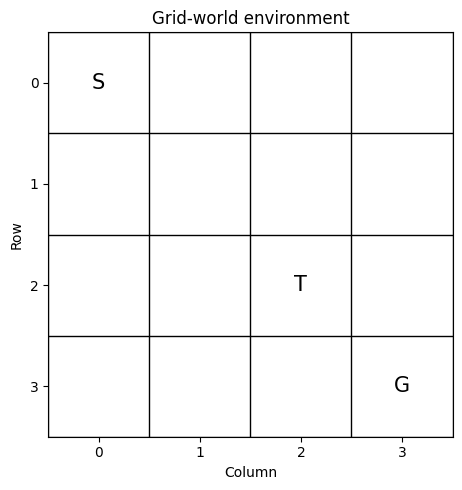

,Current state,Action,Next state,Probability
0,"(1, 1)",right,"(0, 1)",0.0667
2,"(1, 1)",right,"(1, 0)",0.0667
3,"(1, 1)",right,"(1, 2)",0.8000
1,"(1, 1)",right,"(2, 1)",0.0667


Probability sum = 1.0


In [2]:
ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (2, 2)
ACTIONS = ["up", "down", "left", "right"]
DELTAS = {"up": (-1, 0), "down": (1, 0), "left": (0, -1), "right": (0, 1)}
STATES = [(r, c) for r in range(ROWS) for c in range(COLS)]

def move(state, action):
    dr, dc = DELTAS[action]
    r, c = state
    nr, nc = r + dr, c + dc
    return (nr, nc) if 0 <= nr < ROWS and 0 <= nc < COLS else state

def transition_distribution(state, action, intended_prob=0.8):
    probs = defaultdict(float)
    other_prob = (1 - intended_prob) / (len(ACTIONS) - 1)
    for a in ACTIONS:
        p = intended_prob if a == action else other_prob
        probs[move(state, a)] += p
    return dict(probs)

def sample_next_state(state, action, intended_prob=0.8, rng=np.random):
    other_prob = (1 - intended_prob) / (len(ACTIONS) - 1)
    p = [intended_prob if a == action else other_prob for a in ACTIONS]
    chosen = rng.choice(ACTIONS, p=p)
    return move(state, chosen)

def draw_grid(path=None, title="Grid-world environment"):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(np.zeros((ROWS, COLS)), cmap="Greys", vmin=0, vmax=1)
    for r, c in STATES:
        label = "S" if (r,c) == START else "G" if (r,c) == GOAL else "T" if (r,c) == TRAP else ""
        if path and (r,c) in path and (r,c) not in (START, GOAL, TRAP):
            label = "•"
        ax.text(c, r, label, ha="center", va="center", fontsize=15)
    ax.set_xticks(range(COLS)); ax.set_yticks(range(ROWS))
    ax.set_xticks(np.arange(-.5, COLS, 1), minor=True)
    ax.set_yticks(np.arange(-.5, ROWS, 1), minor=True)
    ax.grid(which="minor", color="black", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_title(title); ax.set_xlabel("Column"); ax.set_ylabel("Row")
    plt.tight_layout(); plt.show()

draw_grid()
sample_state, sample_action = (1, 1), "right"
dist = transition_distribution(sample_state, sample_action)
transition_table = pd.DataFrame([{"Current state": sample_state, "Action": sample_action,
                                  "Next state": s, "Probability": round(p, 4)}
                                 for s, p in dist.items()]).sort_values("Next state")
display(transition_table)
print("Probability sum =", round(sum(dist.values()), 6))

### Simulate the Markov model

Actions are chosen uniformly at random. Terminal states are reset to the start so that long-run state visitation can be examined.

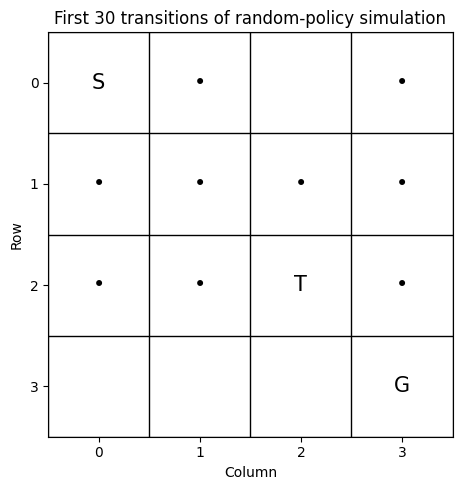

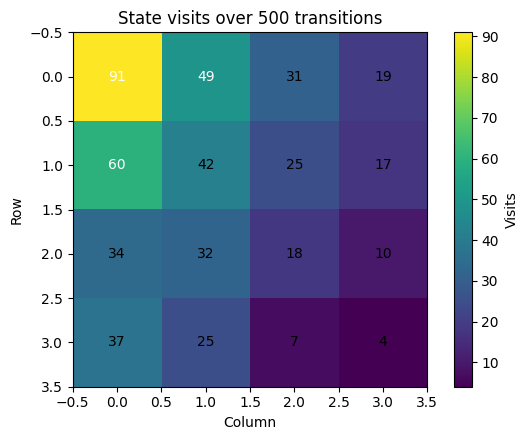

In [3]:
def simulate_random_policy(n_steps=500, seed=7):
    rng = np.random.default_rng(seed)
    state = START
    trajectory = [state]
    visits = defaultdict(int)
    visits[state] += 1
    for _ in range(n_steps):
        if state in (GOAL, TRAP):
            state = START
        action = rng.choice(ACTIONS)
        state = sample_next_state(state, action, rng=rng)
        trajectory.append(state)
        visits[state] += 1
    return trajectory, visits

trajectory, visits = simulate_random_policy()
draw_grid(path=trajectory[:30], title="First 30 transitions of random-policy simulation")
visit_matrix = np.zeros((ROWS, COLS))
for s, count in visits.items():
    visit_matrix[s] = count
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(visit_matrix, cmap="viridis")
for r, c in STATES:
    ax.text(c, r, int(visit_matrix[r,c]), ha="center", va="center",
            color="white" if visit_matrix[r,c] > visit_matrix.max()/2 else "black")
ax.set_title("State visits over 500 transitions")
ax.set_xlabel("Column"); ax.set_ylabel("Row")
plt.colorbar(im, ax=ax, label="Visits")
plt.tight_layout(); plt.show()

## 2. Reward-based decision-making

Rewards: +10 for reaching the goal, −10 for entering the trap, and −1 per ordinary step. Compare reward settings to observe how outcome values change.

In [4]:
BASE_REWARDS = {"goal": 10.0, "trap": -10.0, "step": -1.0}

def reward_for(state, rewards=BASE_REWARDS):
    if state == GOAL: return rewards["goal"]
    if state == TRAP: return rewards["trap"]
    return rewards["step"]

def run_fixed_policy(policy, episodes=200, max_steps=60, rewards=BASE_REWARDS, seed=123):
    rng = np.random.default_rng(seed)
    returns, steps_list, successes = [], [], []
    for _ in range(episodes):
        state, total, steps, success = START, 0.0, 0, False
        for _ in range(max_steps):
            action = policy.get(state, "right")
            state = sample_next_state(state, action, rng=rng)
            total += reward_for(state, rewards)
            steps += 1
            if state == GOAL:
                success = True; break
            if state == TRAP: break
        returns.append(total); steps_list.append(steps); successes.append(success)
    return {"mean_return": float(np.mean(returns)), "mean_steps": float(np.mean(steps_list)),
            "success_rate": float(np.mean(successes))}

# A simple policy that moves right until the final column, then moves down.
policy_toward_goal = {}
for r, c in STATES:
    if (r, c) in (GOAL, TRAP): continue
    policy_toward_goal[(r,c)] = "right" if c < COLS-1 else "down"

reward_scenarios = {
    "Goal +10, trap -10": {"goal": 10, "trap": -10, "step": -1},
    "Goal +30, trap -10": {"goal": 30, "trap": -10, "step": -1},
    "Goal +10, trap -30": {"goal": 10, "trap": -30, "step": -1},
}
reward_rows = []
for name, cfg in reward_scenarios.items():
    result = run_fixed_policy(policy_toward_goal, rewards=cfg, seed=100)
    reward_rows.append({"Reward setting": name, "Mean cumulative reward": round(result["mean_return"],2),
                        "Mean steps": round(result["mean_steps"],2),
                        "Success rate (%)": round(100*result["success_rate"],1)})
display(pd.DataFrame(reward_rows))

,Reward setting,Mean cumulative reward,Mean steps,Success rate (%)
0,"Goal +10, trap -10",0.94,7.67,88.0
1,"Goal +30, trap -10",18.54,7.67,88.0
2,"Goal +10, trap -30",-1.47,7.67,88.0


## 3. Q-learning

Update rule: Q(s,a) ← Q(s,a) + α[r + γ max Q(s′,a′) − Q(s,a)]. For terminal states, the future-value term is zero. Epsilon-greedy action selection explores randomly with probability ε and otherwise selects a currently best action.

Training episodes: 2500
Success rate in last 200 training episodes: 90.5%


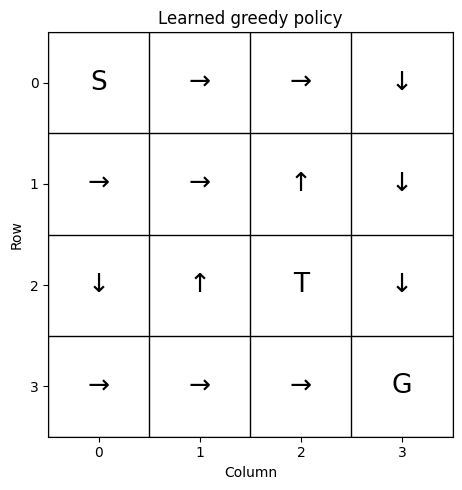

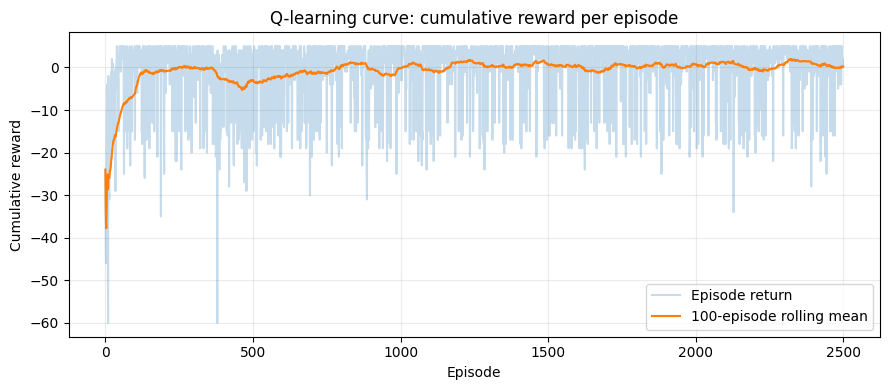

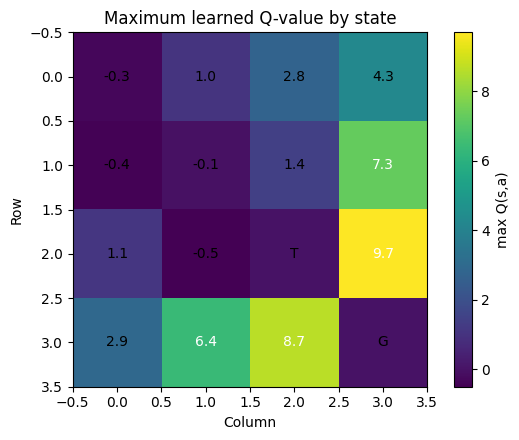

In [5]:
def epsilon_greedy_action(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return rng.choice(ACTIONS)
    values = np.array([Q[state][a] for a in ACTIONS], dtype=float)
    best = np.flatnonzero(values == values.max())
    return ACTIONS[int(rng.choice(best))]

def train_q_learning(episodes=2500, alpha=0.15, gamma=0.95, epsilon=0.2,
                     epsilon_min=0.02, epsilon_decay=0.999, rewards=BASE_REWARDS,
                     max_steps=60, seed=42):
    rng = np.random.default_rng(seed)
    Q = defaultdict(lambda: {a: 0.0 for a in ACTIONS})
    episode_returns, episode_steps, episode_success = [], [], []
    eps = epsilon
    for _ in range(episodes):
        state, total, success, steps = START, 0.0, False, 0
        for _ in range(max_steps):
            action = epsilon_greedy_action(Q, state, eps, rng)
            next_state = sample_next_state(state, action, rng=rng)
            reward = reward_for(next_state, rewards)
            terminal = next_state in (GOAL, TRAP)
            future = 0.0 if terminal else max(Q[next_state].values())
            Q[state][action] += alpha * (reward + gamma*future - Q[state][action])
            state = next_state; total += reward; steps += 1
            if state == GOAL:
                success = True; break
            if state == TRAP: break
        episode_returns.append(total); episode_steps.append(steps); episode_success.append(success)
        eps = max(epsilon_min, eps*epsilon_decay)
    return Q, np.array(episode_returns), np.array(episode_steps), np.array(episode_success)

def greedy_policy(Q):
    policy = {}
    for state in STATES:
        if state in (GOAL, TRAP): continue
        policy[state] = ACTIONS[int(np.argmax([Q[state][a] for a in ACTIONS]))]
    return policy

ARROWS = {"up":"↑", "down":"↓", "left":"←", "right":"→"}
def plot_policy(policy, title="Learned greedy policy"):
    fig, ax = plt.subplots(figsize=(5,5))
    ax.imshow(np.zeros((ROWS,COLS)), cmap="Greys", vmin=0, vmax=1)
    for r,c in STATES:
        label = "S" if (r,c)==START else "G" if (r,c)==GOAL else "T" if (r,c)==TRAP else ARROWS.get(policy.get((r,c),""), "?")
        ax.text(c,r,label,ha="center",va="center",fontsize=19)
    ax.set_xticks(range(COLS)); ax.set_yticks(range(ROWS))
    ax.set_xticks(np.arange(-.5,COLS,1),minor=True); ax.set_yticks(np.arange(-.5,ROWS,1),minor=True)
    ax.grid(which="minor",color="black",linewidth=1); ax.tick_params(which="minor",bottom=False,left=False)
    ax.set_title(title); ax.set_xlabel("Column"); ax.set_ylabel("Row")
    plt.tight_layout(); plt.show()

Q, train_returns, train_steps, train_success = train_q_learning()
learned_policy = greedy_policy(Q)
print("Training episodes:", len(train_returns))
print("Success rate in last 200 training episodes: %.1f%%" % (100*train_success[-200:].mean()))
plot_policy(learned_policy)

window = 100
rolling = pd.Series(train_returns).rolling(window, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(train_returns, alpha=0.25, label="Episode return")
ax.plot(rolling, label="100-episode rolling mean")
ax.set_title("Q-learning curve: cumulative reward per episode")
ax.set_xlabel("Episode"); ax.set_ylabel("Cumulative reward"); ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

value_matrix = np.zeros((ROWS,COLS))
for s in STATES:
    value_matrix[s] = 0 if s in (GOAL,TRAP) else max(Q[s].values())
fig, ax = plt.subplots(figsize=(6,4.5))
im = ax.imshow(value_matrix, cmap="viridis")
for r,c in STATES:
    label = "G" if (r,c)==GOAL else "T" if (r,c)==TRAP else f"{value_matrix[r,c]:.1f}"
    ax.text(c,r,label,ha="center",va="center",color="white" if value_matrix[r,c] > value_matrix.max()/2 else "black")
ax.set_title("Maximum learned Q-value by state"); ax.set_xlabel("Column"); ax.set_ylabel("Row")
plt.colorbar(im,ax=ax,label="max Q(s,a)"); plt.tight_layout(); plt.show()

## 4. Exploration vs. exploitation

Compare initial epsilon values while keeping the other settings constant. Higher epsilon explores more; lower epsilon exploits current estimates more often. Each learned greedy policy is evaluated separately.

,Initial epsilon,Evaluation mean reward,Mean steps,Success rate (%),Training success last 200 (%)
0,0.05,1.47,7.73,91.0,87.5
1,0.20,-1.39,9.84,87.0,82.0
2,0.50,1.26,7.82,90.4,90.5


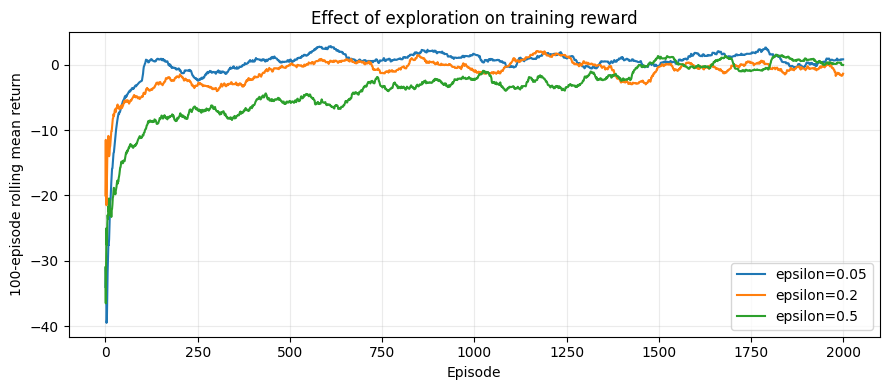

In [6]:
def evaluate_policy(policy, episodes=500, max_steps=60, rewards=BASE_REWARDS, seed=202):
    rng = np.random.default_rng(seed)
    returns, steps_list, successes = [], [], []
    for _ in range(episodes):
        state, total, steps, success = START, 0.0, 0, False
        for _ in range(max_steps):
            action = policy.get(state, "right")
            state = sample_next_state(state, action, rng=rng)
            total += reward_for(state, rewards); steps += 1
            if state == GOAL: success = True; break
            if state == TRAP: break
        returns.append(total); steps_list.append(steps); successes.append(success)
    return {"mean_return": np.mean(returns), "mean_steps": np.mean(steps_list),
            "success_rate": np.mean(successes)}

epsilon_values = [0.05, 0.2, 0.5]
epsilon_rows, epsilon_runs = [], {}
for i, eps in enumerate(epsilon_values):
    q, rets, stps, succ = train_q_learning(episodes=2000, epsilon=eps, seed=1000+i)
    pol = greedy_policy(q); ev = evaluate_policy(pol, seed=3000+i)
    epsilon_runs[eps] = (rets, pol, ev)
    epsilon_rows.append({"Initial epsilon":eps, "Evaluation mean reward":round(ev["mean_return"],2),
                         "Mean steps":round(ev["mean_steps"],2), "Success rate (%)":round(100*ev["success_rate"],1),
                         "Training success last 200 (%)":round(100*succ[-200:].mean(),1)})
display(pd.DataFrame(epsilon_rows))

fig, ax = plt.subplots(figsize=(9,4))
for eps, (rets, _, _) in epsilon_runs.items():
    ax.plot(pd.Series(rets).rolling(100,min_periods=1).mean(), label=f"epsilon={eps}")
ax.set_title("Effect of exploration on training reward"); ax.set_xlabel("Episode")
ax.set_ylabel("100-episode rolling mean return"); ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 5. Discount factor γ

A lower γ emphasizes immediate rewards, while a higher γ gives greater weight to future rewards. We compare the greedy policies learned under several discount factors.

,Gamma,Evaluation mean reward,Mean steps,Success rate (%)
0,0.50,0.26,8.90,90.8
1,0.80,1.57,7.71,91.4
2,0.95,0.85,7.75,88.0
3,0.99,1.10,7.82,89.6


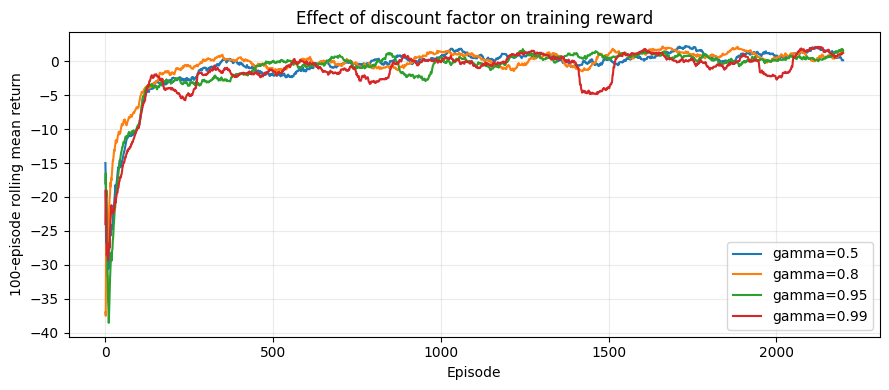

In [7]:
gamma_values = [0.5, 0.8, 0.95, 0.99]
gamma_rows, gamma_runs = [], {}
for i, gamma in enumerate(gamma_values):
    q, rets, stps, succ = train_q_learning(episodes=2200, gamma=gamma, epsilon=0.2, seed=500+i)
    pol = greedy_policy(q); ev = evaluate_policy(pol, seed=700+i)
    gamma_runs[gamma] = (rets, pol, ev)
    gamma_rows.append({"Gamma":gamma, "Evaluation mean reward":round(ev["mean_return"],2),
                       "Mean steps":round(ev["mean_steps"],2), "Success rate (%)":round(100*ev["success_rate"],1)})
display(pd.DataFrame(gamma_rows))

fig, ax = plt.subplots(figsize=(9,4))
for gamma, (rets, _, _) in gamma_runs.items():
    ax.plot(pd.Series(rets).rolling(100,min_periods=1).mean(), label=f"gamma={gamma}")
ax.set_title("Effect of discount factor on training reward"); ax.set_xlabel("Episode")
ax.set_ylabel("100-episode rolling mean return"); ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 6. Policy evaluation

Compare mean cumulative reward, mean steps, and success rate across the default policy and the epsilon/gamma experiments. Success rate is the fraction of evaluation episodes reaching the goal. Because transitions are stochastic, results can vary by random seed.

,Setting,Mean cumulative reward,Mean steps,Success rate (%)
0,Epsilon 0.5,1.45,7.71,90.8
1,Epsilon 0.05,1.42,7.72,90.7
2,Gamma 0.8,1.46,7.66,90.6
3,Gamma 0.99,1.36,7.72,90.4
4,Gamma 0.95,1.33,7.71,90.2
5,Default Q-learning,0.70,8.24,89.7
6,Epsilon 0.2,-1.19,10.06,89.1
7,Gamma 0.5,-0.17,8.51,86.7


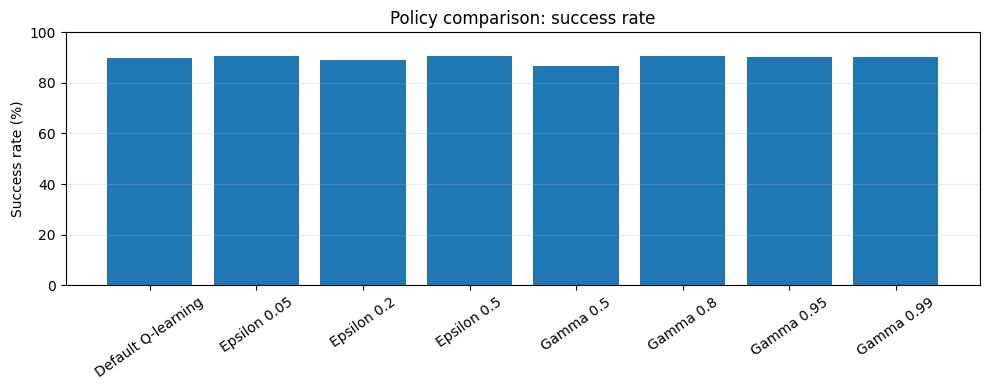

In [8]:
comparison_rows = []
policies_to_compare = [("Default Q-learning", learned_policy)]
policies_to_compare += [(f"Epsilon {eps}", data[1]) for eps, data in epsilon_runs.items()]
policies_to_compare += [(f"Gamma {gamma}", data[1]) for gamma, data in gamma_runs.items()]
for label, policy in policies_to_compare:
    ev = evaluate_policy(policy, episodes=1000, seed=900)
    comparison_rows.append({"Setting":label, "Mean cumulative reward":round(ev["mean_return"],2),
                            "Mean steps":round(ev["mean_steps"],2), "Success rate (%)":round(100*ev["success_rate"],1)})
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.sort_values("Success rate (%)",ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10,4))
ax.bar(comparison_df["Setting"], comparison_df["Success rate (%)"])
ax.set_title("Policy comparison: success rate"); ax.set_ylabel("Success rate (%)"); ax.set_ylim(0,100)
ax.tick_params(axis="x",rotation=35); ax.grid(axis="y",alpha=0.25)
plt.tight_layout(); plt.show()

## Result and conclusion

- The Markov model describes probabilistic transitions between states; simulation and state-visit counts illustrate behavior under a random policy.
- Rewards define desirable and undesirable outcomes, influencing the policy learned by Q-learning.
- Q-learning estimates action values and derives a greedy policy; the learning curve tracks cumulative episode rewards.
- Epsilon balances exploration and exploitation, while gamma controls the importance of future rewards.
- Policy evaluation uses cumulative reward, steps taken, and success rate. Since the environment is stochastic, compare measured results rather than assuming a single parameter setting is always best.

**Experiment 9 completed.**